In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

churn = pd.read_csv("../data/processed/churn_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", churn.shape)

churn.head()

Dataset loaded successfully!
Shape: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
def assign_segment(row):
    if row["IsActiveMember"] == 1 and row["NumOfProducts"] == 1:
        return "Active Single-Product"

    elif row["IsActiveMember"] == 1 and row["NumOfProducts"] > 1:
        return "Active Multi-Product"

    elif row["IsActiveMember"] == 0 and row["NumOfProducts"] == 1:
        return "Inactive Single-Product"

    else:
        return "Inactive Multi-Product"


churn["Customer_Segment"] = churn.apply(assign_segment, axis=1)

churn[["IsActiveMember", "NumOfProducts", "Customer_Segment"]].head(10)

,IsActiveMember,NumOfProducts,Customer_Segment
0,1,1,Active Single-Product
1,1,1,Active Single-Product
2,0,3,Inactive Multi-Product
3,0,2,Inactive Multi-Product
4,1,1,Active Single-Product
5,0,2,Inactive Multi-Product
6,1,2,Active Multi-Product
7,0,4,Inactive Multi-Product
8,1,2,Active Multi-Product
9,1,1,Active Single-Product


In [3]:
segment_distribution = churn["Customer_Segment"].value_counts().reset_index()

segment_distribution.columns = ["Customer_Segment", "Total_Customers"]

segment_distribution["Percentage"] = (
    segment_distribution["Total_Customers"] / len(churn) * 100
).round(2)

segment_distribution

,Customer_Segment,Total_Customers,Percentage
0,Active Multi-Product,2588,25.88
1,Active Single-Product,2563,25.63
2,Inactive Single-Product,2521,25.21
3,Inactive Multi-Product,2328,23.28


In [4]:
segment_profile = churn.groupby("Customer_Segment").agg(
    Total_Customers=("Exited", "count"),
    Average_Age=("Age", "mean"),
    Average_Balance=("Balance", "mean"),
    Average_Tenure=("Tenure", "mean"),
    Average_Products=("NumOfProducts", "mean"),
    Churn_Rate=("Exited", "mean")
).reset_index()

segment_profile["Churn_Rate"] = (
    segment_profile["Churn_Rate"] * 100
).round(2)

segment_profile = segment_profile.round(2)

segment_profile

,Customer_Segment,Total_Customers,Average_Age,Average_Balance,Average_Tenure,Average_Products,Churn_Rate
0,Active Multi-Product,2588,39.34,53071.26,4.98,2.07,9.66
1,Active Single-Product,2563,40.25,98902.02,4.89,1.00,18.92
2,Inactive Multi-Product,2328,36.82,54326.79,5.13,2.09,16.24
3,Inactive Single-Product,2521,39.09,98195.89,5.06,1.00,36.65


In [5]:
segment_churn = churn.groupby("Customer_Segment").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

segment_churn["Churn_Rate"] = (
    segment_churn["Churn_Rate"] * 100
).round(2)

segment_churn

,Customer_Segment,Total_Customers,Churned_Customers,Churn_Rate
0,Active Multi-Product,2588,250,9.66
1,Active Single-Product,2563,485,18.92
2,Inactive Multi-Product,2328,378,16.24
3,Inactive Single-Product,2521,924,36.65


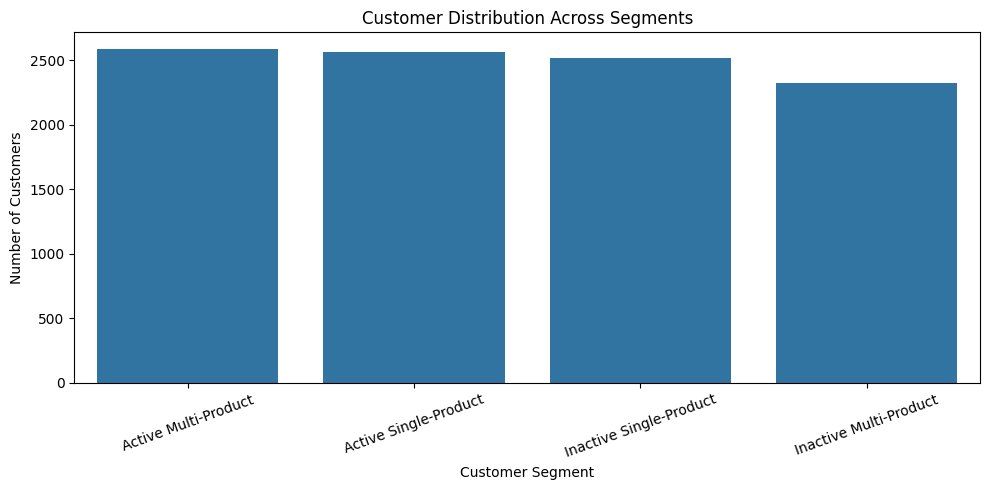

In [6]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_distribution,
    x="Customer_Segment",
    y="Total_Customers"
)

plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

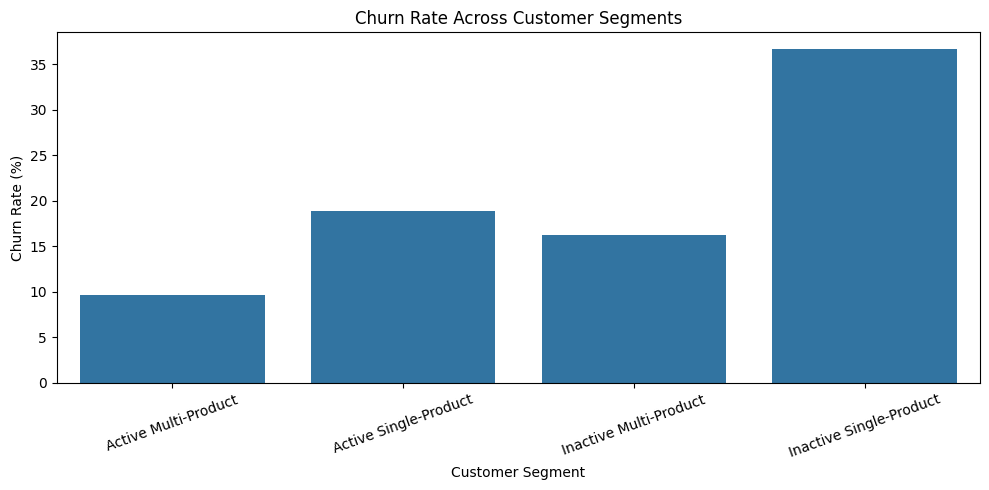

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_churn,
    x="Customer_Segment",
    y="Churn_Rate"
)

plt.title("Churn Rate Across Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [8]:
churn.to_csv(
    "../data/processed/customer_segments.csv",
    index=False
)

segment_distribution.to_csv(
    "../data/processed/customer_segment_distribution.csv",
    index=False
)

segment_profile.to_csv(
    "../data/processed/customer_segment_profile.csv",
    index=False
)

segment_churn.to_csv(
    "../data/processed/customer_segment_churn.csv",
    index=False
)

print("Customer segmentation files saved successfully!")

Customer segmentation files saved successfully!
